# Corporate Knowledge Assistant: ответы по PDF-инструкциям и Wiki со ссылками на страницы

Домашнее задание курса LLM. Ассистент отвечает на вопросы сотрудников по внутренней
базе знаний и подтверждает каждый факт ссылкой вида **[Файл.pdf, стр. X]** или
**[Название Wiki-статьи]**. Главный вопрос работы: можно ли доверять этим ссылкам
и где они ломаются.

Ноутбук читается без запуска: все выводы сохранены. Ответы модели — реальные прогоны
YandexGPT 5 Lite, они лежат в `outputs/` и `outputs/llm_cache/`, поэтому повторный
запуск работает без API-ключа и бесплатно (`LLM_MODE=replay`).

| Компонент | Выбор |
| --- | --- |
| База знаний | корпус «РобоТех» из репозитория урока ([Ilia2704/rag-llamaindex](https://github.com/Ilia2704/rag-llamaindex), `data/knowledge_base`), упакованный в 4 PDF-сборника и 4 Wiki-страницы |
| Парсинг PDF | **PyMuPDF** (`get_text("dict")`: шрифты, координаты, PageLabels) |
| Парсинг HTML | **BeautifulSoup** + lxml |
| Чанкование | LangChain `RecursiveCharacterTextSplitter`, 400 символов, перекрытие 80, чанк не пересекает страницу |
| Эмбеддинги | `intfloat/multilingual-e5-base`, локально (Apple MPS) |
| Векторная база | **ChromaDB**, метаданные хранятся с каждым вектором |
| Retriever | top-5 по косинусной близости |
| LLM | **YandexGPT 5 Lite** (`yandexgpt-lite/latest`), temperature 0.1, OpenAI-совместимый API Yandex AI Studio |

## 0. Окружение

In [1]:
import json, sys, re, inspect, os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
os.environ.setdefault("LLM_MODE", "replay")
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ["TQDM_DISABLE"] = "1"                 # без прогресс-баров загрузки модели
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("sentence_transformers").setLevel(logging.ERROR)

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

mpl.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_colwidth", 90)

from src import config
from src.config import ChunkConfig

def load(name):
    return json.loads((ROOT / "outputs" / f"{name}.json").read_text(encoding="utf-8"))

print("LLM:", config.YC_MODEL, "| режим:", config.LLM_MODE, "| эмбеддинги:", config.EMBED_MODEL)
print("чанки:", config.DEFAULT_CHUNKS, "| top-K:", config.TOP_K)

LLM: yandexgpt-lite/latest | режим: replay | эмбеддинги: intfloat/multilingual-e5-base
чанки: ChunkConfig(chunk_size=400, chunk_overlap=80, strategy='page', clean=True) | top-K: 5


## 1. База знаний

Задание предлагает найти свой датасет. В материалах урока уже есть готовый корпус
вымышленной компании **РобоТех**: 36 markdown-документов (HR, ИБ, проекты, закупки и
24 «шумовых» документа). Он взят без изменений текста — так факты не придуманы мной,
а тестовые вопросы проверяются по чужому, заранее существующему тексту.

Но в корпусе нет ни одного PDF и ни одной HTML-страницы, а смысл задания — именно в
них. Поэтому `tools/build_corpus.py` переупаковывает документы так, как выглядят
настоящие корпоративные инструкции:

* **4 PDF-сборника** (главы идут сплошным потоком, раздел может начаться внизу одной
  страницы и закончиться на следующей). На каждой странице колонтитулы, а **титул и
  оглавление не нумеруются**: напечатанная «— 1 —» стоит на физической странице 3.
  Это обычная ситуация для реальных PDF и главная ловушка для номеров страниц.
* **4 Wiki-страницы** в виде HTML-экспорта: шапка с меню, «хлебные крошки», боковая
  панель со ссылками на соседние статьи, подвал. Полезный текст — только в `<article>`.

Ссылка на страницу в ответе — **физический номер** (его открывает `файл.pdf#page=N` в
любом просмотрщике). Напечатанный номер и метка PageLabels хранятся в метаданных
отдельно (`page_label`).

In [2]:
import pymupdf
rows = []
for name, spec in config.PDF_BOOKS.items():
    with pymupdf.open(config.PDF_DIR / name) as d:
        rows.append({"файл": name, "тип": "PDF", "страниц": d.page_count,
                     "документов-глав": len(spec["chapters"]),
                     "метки страниц": ", ".join(p.get_label() for p in d)})
for name, spec in config.WIKI_PAGES.items():
    from src.parsing import parse_html
    rows.append({"файл": name, "тип": "Wiki HTML", "страниц": "—", "документов-глав": 1,
                 "метки страниц": parse_html(config.WIKI_DIR / name)[0].title})
pd.DataFrame(rows)

,файл,тип,страниц,документов-глав,метки страниц
0,Справочник_сотрудника_HR.pdf,PDF,11,11,"i, ii, 1, 2, 3, 4, 5, 6, 7, 8, 9"
1,Регламенты_ИТ_и_безопасности.pdf,PDF,11,12,"i, ii, 1, 2, 3, 4, 5, 6, 7, 8, 9"
2,Инструкции_по_офису_и_закупкам.pdf,PDF,7,7,"i, ii, 1, 2, 3, 4, 5"
3,Архив_HR_2024.pdf,PDF,4,2,"i, ii, 1, 2"
4,Project_Atlas.html,Wiki HTML,—,1,Проект Atlas: графовая навигация по корпоративным знаниям
5,Meeting_Atlas_Security_2026-03-14.html,Wiki HTML,—,1,Встреча Atlas и Security по графовому RAG
6,Project_Red_Eye.html,Wiki HTML,—,1,"Проект ""Красный Глаз"" (Red Eye)"
7,Meeting_Corporate_NewYear_2025.html,Wiki HTML,—,1,"Протокол Встречи по Новогоднему Корпоративу, 10.12.2025"


Так выглядят страницы справочника: титул, оглавление (номера в нём — печатные) и страница с колонтитулами.

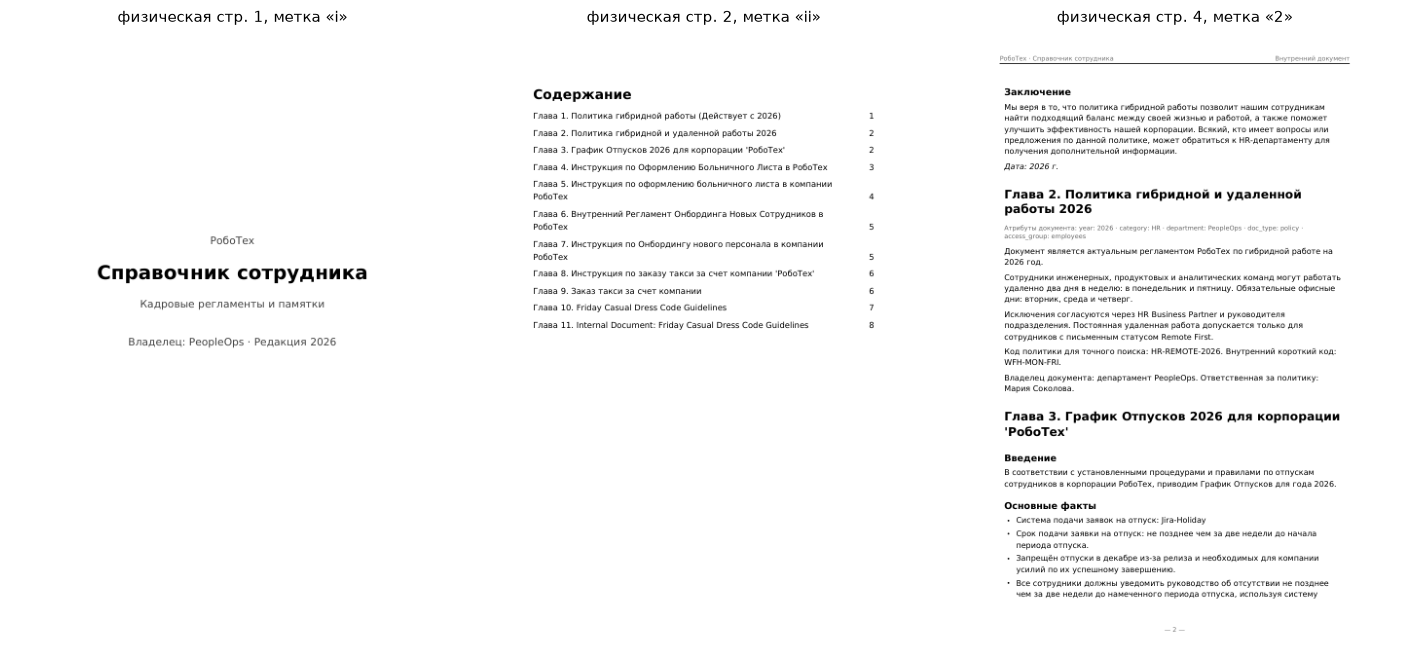

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 6))
with pymupdf.open(config.PDF_DIR / "Справочник_сотрудника_HR.pdf") as d:
    for ax, i in zip(axes, (0, 1, 3)):
        pix = d[i].get_pixmap(dpi=55)
        import numpy as np
        img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.h, pix.w, pix.n)
        ax.imshow(img); ax.set_axis_off()
        ax.set_title(f"физическая стр. {i+1}, метка «{d[i].get_label()}»", fontsize=10)
plt.tight_layout(); plt.show()

## 2. Парсинг с метаданными

### 2.1. Почему не хватает `page.get_text()`

Вот что отдаёт «наивное» извлечение текста со страницы 4. Колонтитул и печатный
номер «— 2 —» оказываются **в начале** текста страницы (PDF рисует их раньше основного
текста), а про заголовок раздела в тексте не сказано ничего.

In [4]:
from src.parsing import naive_pdf_pages
print(naive_pdf_pages(config.PDF_DIR / "Справочник_сотрудника_HR.pdf")[3][1][:600])

РобоТех · Справочник сотрудника
Внутренний документ
— 2 —
Заключение
Мы веря в то, что политика гибридной работы позволит нашим сотрудникам
найти подходящий баланс между своей жизнью и работой, а также поможет
улучшить эффективность нашей корпорации. Всякий, кто имеет вопросы или
предложения по данной политике, может обратиться к HR-департаменту для
получения дополнительной информации.
Дата: 2026 г.
Глава 2. Политика гибридной и удаленной
работы 2026
Атрибуты документа: year: 2026 · category: HR · department: PeopleOps · doc_type: policy ·
access_group: employees
Документ является актуальным р


### 2.2. Как извлекаются и прикрепляются метаданные (артефакт для отчёта)

`parse_pdf` читает страницу построчно вместе со шрифтом и координатами
(`get_text("dict")`) и делает четыре вещи:

1. **страница** — номер берётся из цикла по страницам (`pno + 1`), печатная метка — из
   PageLabels (`page.get_label()`);
2. **колонтитулы** — строки в верхних и нижних 7% высоты страницы отбрасываются по
   геометрии, а не по тексту;
3. **титул и оглавление** — пропускаются: у них метка не число (i, ii), либо страница
   похожа на оглавление (заголовок «Содержание», много строк, кончающихся числом);
4. **заголовок раздела** — жирная строка ≥ 12 pt становится `header`, ≥ 15 pt —
   `chapter`. Заголовок **переносится через границу страницы**: продолжение раздела на
   следующей странице получает тот же `header`.

In [5]:
from src import parsing
print(inspect.getsource(parsing.parse_pdf))

def parse_pdf(path: Path, clean: bool = True) -> list[Segment]:
    doc = pymupdf.open(path)
    title = doc.metadata.get("title") or path.stem
    segments: list[Segment] = []
    chapter, header = "", ""

    for pno in range(doc.page_count):
        page = doc[pno]
        label = page.get_label() or str(pno + 1)
        h = page.rect.height
        blocks = _blocks(page)
        # Титул и оглавление: либо метка страницы не число (i, ii), либо страница
        # похожа на оглавление (для PDF без PageLabels).
        if clean and (not label.isdigit() or _is_toc_page(blocks)):
            continue

        buf: list[str] = []

        def flush() -> None:
            text = "\n".join(buf).strip()
            if text:
                segments.append(Segment(path.name, "pdf", title, pno + 1, label,
                                        chapter, header, text))
            buf.clear()

        for lines in blocks:
            if clean:
                lines = [ln for ln in lines
       

Результат — сегменты «одна страница × один раздел». Начало справочника:

In [6]:
from src.parsing import parse_pdf
segs = parse_pdf(config.PDF_DIR / "Справочник_сотрудника_HR.pdf")
pd.DataFrame([{"page": s.page, "page_label": s.page_label, "chapter": s.chapter[:40],
               "header": s.header[:35], "текст": s.text[:70].replace("\n", " ")}
              for s in segs[:10]])

,page,page_label,chapter,header,текст
0,3,1,Политика гибридной работы (Действует с 2,Вступление,В соответствии с нашими корпоративными целями по улучшению эффективнос
1,3,1,Политика гибридной работы (Действует с 2,Главный текст,Статус: Активен Наши сотрудники могут выбирать между гибридной работой
2,3,1,Политика гибридной работы (Действует с 2,Правила гибридной работы:,"• Вход в офис: Все сотрудники должны присутствовать во Вторник, Среду,"
3,4,2,Политика гибридной работы (Действует с 2,Заключение,"Мы веря в то, что политика гибридной работы позволит нашим сотрудникам"
4,4,2,Политика гибридной и удаленной работы 20,Политика гибридной и удаленной рабо,Атрибуты документа: year: 2026 · category: HR · department: PeopleOps
5,4,2,График Отпусков 2026 для корпорации 'Роб,Введение,В соответствии с установленными процедурами и правилами по отпускам со
6,4,2,График Отпусков 2026 для корпорации 'Роб,Основные факты,• Система подачи заявок на отпуск: Jira-Holiday • Срок подачи заявки н
7,5,3,График Отпусков 2026 для корпорации 'Роб,Основные факты,Jira-Holiday. • В случае изменения или отмены планов по отпуску обязат
8,5,3,График Отпусков 2026 для корпорации 'Роб,Заключение,График Отпусков 2026 для всех сотрудников корпорации РобоТех определён
9,5,3,Инструкция по Оформлению Больничного Лис,Инструкция по Оформлению Больничног,В приложении представлена Памятка по Оформлению Больничного Листа для


Видно главное: раздел «Основные факты» графика отпусков начинается на стр. 4 и
продолжается на стр. 5, и у продолжения `header` сохранён. Без этого фрагмент со
стр. 5 («…сообщить руководству в течение 48 часов») был бы безымянным.

### 2.3. HTML (Wiki)

`parse_html` выкидывает `header/nav/aside/footer` и «хлебные крошки», название статьи
берёт из `<h1>`, разделы — из `<h2>`. Для сравнения — сколько мусора даёт сырой
`get_text()` всей страницы: в боковой панели перечислены названия **других** статей,
и без чистки они попадают в чанк и в поиск.

In [7]:
from src.parsing import parse_html, wiki_meta
p = config.WIKI_DIR / "Meeting_Atlas_Security_2026-03-14.html"
raw = parse_html(p, clean=False)[0].text
clean = parse_html(p)
print("СЫРОЙ ТЕКСТ (начало):\n", raw[:420], "\n")
print("ПОСЛЕ ЧИСТКИ:", [(s.header, s.text[:60]) for s in clean][:3])
print("\nметаданные из <meta>:", wiki_meta(p))

СЫРОЙ ТЕКСТ (начало):
 РобоТех Wiki
|
Пространства
|
Люди
|
Поиск
Пространство AI Platform
Проект Atlas: графовая навигация по корпоративным знаниям
Проект "Красный Глаз" (Red Eye)
Протокол Встречи по Новогоднему Корпоративу, 10.12.2025
РобоТех Wiki / AI Platform / Встреча Atlas и Security по графовому RAG
Встреча Atlas и Security по графовому RAG
Дата: 2026-03-14.
Участники: Иван Петров, Мария Соколова, Анна Ким, команда Security, команда 

ПОСЛЕ ЧИСТКИ: [('Встреча Atlas и Security по графовому RAG', 'Дата: 2026-03-14.\nУчастники: Иван Петров, Мария Соколова, Ан')]

метаданные из <meta>: {'space': 'AI Platform', 'year': '2026', 'category': 'Projects', 'department': 'AI_Platform', 'doc_type': 'meeting_notes', 'access_group': 'engineering', 'graph_ready': 'true'}


## 3. Чанкование: метаданные жёстко привязаны к чанку

Каждый сегмент режется отдельно (`RecursiveCharacterTextSplitter`, 400/80), поэтому
чанк **никогда не пересекает границу страницы** и у него ровно один номер страницы.
Словарь метаданных уходит в ChromaDB без изменений:

In [8]:
from src.index import build, all_chunks
print(build())
chunks = all_chunks()
ex = next(c for c in chunks if "48 часов" in c.text)
print("\nтекст чанка:", ex.text[:160], "...")
print("\nметаданные:", json.dumps(ex.meta, ensure_ascii=False, indent=1))

{'collection': 'page-400-80-clean', 'chunks': 171, 'cached': True}

текст чанка: Jira-Holiday.
• В случае изменения или отмены планов по отпуску обязательно сообщить руководству в течение 48 часов.
• Сотрудники должны указать контактную инфо ...

метаданные: {
 "source": "Справочник_сотрудника_HR.pdf",
 "chunk_id": "Справочник_сотрудника_HR.pdf#012",
 "title": "Справочник сотрудника",
 "chapter": "График Отпусков 2026 для корпорации 'РобоТех'",
 "page": 5,
 "page_end": 5,
 "page_label": "3",
 "doc_type": "pdf",
 "header": "Основные факты"
}


В эмбеддинг дополнительно уходит «хлебная крошка» `глава / раздел` — короткий пункт
списка «• Срок подачи заявки: не позднее…» без неё почти не находится (заявки на что?).
Модели и пользователю показывается исходный текст.

## 4. Векторная база и Retriever

In [9]:
from src.index import retrieve
for h in retrieve("За сколько дней нужно писать заявление на отпуск?"):
    print(f"{h.score:.3f}  {h.ref():45s} header={h.meta['header']!r:28s} {h.text[:55]!r}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

0.861  [Справочник_сотрудника_HR.pdf, стр. 5]        header='Основные факты'             'Jira-Holiday.\n• В случае изменения или отмены планов по'
0.848  [Справочник_сотрудника_HR.pdf, стр. 4]        header='Основные факты'             '• Система подачи заявок на отпуск: Jira-Holiday\n• Срок '
0.828  [Справочник_сотрудника_HR.pdf, стр. 6]        header='Инструкция по оформлению больничного листа в компании РобоТех' 'Замечание: В случае необходимости длительного отсутстви'
0.821  [Справочник_сотрудника_HR.pdf, стр. 5]        header='Заключение'                 'Подпись: [имя руководителя по делам персонала] Дата: [д'
0.814  [Архив_HR_2024.pdf, стр. 3]                   header='II. Главные факты'          '1. Год документа: 2024.\n2. Статус: Архив.\n3. Правило: Р'


Retriever возвращает top-5 чанков **вместе с метаданными**: из них собирается и
контекст для модели, и проверка ссылок. Обратите внимание: первым идёт чанк со
стр. 5 — продолжение того же раздела. Нужный факт («две недели») лежит во втором
чанке на стр. 4. Если бы страница определялась по «самому релевантному» чанку,
ссылка была бы неверной; здесь страницу выбирает модель по блоку, откуда взят факт.

## 5. Система цитирования (prompt engineering)

### 5.1. Контекст с явным указанием источника

Формат блока — как в задании, плюс две добавки: название раздела и **готовая ссылка**
в нужном формате. Модели не нужно собирать ссылку из частей — только скопировать её;
номер страницы приходит из метаданных, а не из текста.

In [10]:
from src.prompts import format_context, SYSTEM_STRICT, SYSTEM_BASIC
print(format_context(retrieve("Что нужно для доступа к Neo4j и в каком проекте он используется?")[:3]))

Контекст 1 (Источник: Wiki «Проект Atlas: графовая навигация по корпоративным знаниям»; ссылка: [Проект Atlas: графовая навигация по корпоративным знаниям]):
Проект Atlas использует LlamaIndex PropertyGraphIndex для извлечения сущностей и отношений из документов. Граф хранится в Neo4j. Векторные чанки и hybrid search хранятся в Qdrant.
Команда AI Platform отвечает за RAG pipeline. Команда Security отвечает за требования ZTA-17. Команда PeopleOps отвечает за политику HR-REMOTE-2026.
Ключевые связи:
• Мария Соколова owns HR-REMOTE-2026.

Контекст 2 (Источник: Регламенты_ИТ_и_безопасности.pdf, стр. 3; раздел «Стандарт доступа Zero Trust 2026»; ссылка: [Регламенты_ИТ_и_безопасности.pdf, стр. 3]):
Атрибуты документа: year: 2026 · category: IT_Security · department: Security · doc_type: standard · access_group: employees
С 2026 года все инженерные сервисы РобоТех подключаются через Zero Trust Access. Внутренний код стандарта: ZTA-17.
Для доступа к Qdrant, Neo4j, GitHub Actions и окружениям c

### 5.2. Итоговый системный промпт (артефакт для отчёта)

In [11]:
print(SYSTEM_STRICT)

Ты — корпоративный ассистент компании РобоТех. Твоя задача — отвечать на вопросы сотрудников.

Правила:
1. Отвечай строго и только на основе предоставленного контекста. Не используй собственные знания, законы, «обычную практику» и догадки. Если ответа нет в тексте, напиши ровно: «Я не знаю» — и больше ничего не добавляй.
2. Подтверждай каждый факт ссылкой на источник. Формат ссылки должен быть строго таким: [Название файла, стр. X] или [Название Wiki-статьи]. Ссылка ставится в конце того предложения или пункта списка, который она подтверждает. Каждый абзац и каждый пункт списка должен заканчиваться ссылкой.
3. Бери ссылку только из заголовка того блока контекста, откуда взят факт (поле «ссылка»). Номер страницы бери только оттуда. Числа внутри текста фрагмента не являются номерами страниц.
4. Никогда не придумывай файлы, страницы и статьи, которых нет в заголовках блоков контекста. Если факт подтверждают два блока, поставь обе ссылки: [A, стр. X][B, стр. Y].
5. Если вопрос требует свед

Первые три правила — дословно требования задания. Остальные появились из
тестирования: правило 3 — против номеров страниц из текста (колонтитулов и
оглавления, см. § 7.3), 4 — против выдуманных источников, 6 — про архивные и
противоречащие друг другу документы, 7 — для частичного ответа.

Для сравнения все тесты прогнаны и с **базовым** промптом — только три обязательных
правила задания:

In [12]:
print(SYSTEM_BASIC)

Ты — корпоративный ассистент. Твоя задача — отвечать на вопросы сотрудников.
Отвечай строго и только на основе предоставленного контекста. Если ответа нет в тексте, напиши 'Я не знаю'.
Подтверждай каждый факт ссылкой на источник. Формат ссылки должен быть строго таким: [Название файла, стр. X] или [Название Wiki-статьи].


## 6. Тестирование: логи

15 вопросов четырёх типов: 5 прямых, 4 на агрегацию, 3 провокации вне базы, 3 с
длинным ответом. Каждая ссылка в ответе проверяется автоматически:

* **статус ссылки** — есть ли такой файл, есть ли в нём такая страница, был ли этот
  фрагмент в контексте модели (`ok / not_in_context / bad_page / fabricated`);
* **подтверждение факта** — содержит ли цитируемая страница PDF *на самом деле*
  нужную фразу. Проверяется по тексту страницы в файле, а не по метаданным чанка;
  правильные страницы не размечены руками, а найдены поиском фразы по PDF.

Ниже — 6 показательных вопросов полностью: ответ ассистента с кликабельными ссылками
(PDF открывается сразу на нужной странице), найденные фрагменты и вердикт проверки.
Полный лог всех 15 вопросов — в [`docs/test_log.md`](../docs/test_log.md).

In [13]:
from src.citations import linkify
main = load("exp_main")
TYPE_RU = {"direct": "прямой вопрос", "aggregation": "агрегация", "ood": "провокация (вне базы)",
           "long": "длинный ответ"}

def show(r):
    g = r["grade"]
    out = [f"### {r['id']} · {TYPE_RU[r['type']]}", f"**Вопрос:** {r['question']}", "",
           "**Ответ ассистента:**", "", "> " + linkify(r["answer"]).replace("\n", "\n> "), ""]
    if r.get("subqueries"):
        out.append("*Подвопросы для поиска:* " + " · ".join(r["subqueries"]))
    out.append("*Найденные фрагменты:* " + ", ".join(f"`{h['ref']}`" for h in r["hits"]))
    cites = ", ".join(f"`[{c['raw']}]` → {c['status']}" for c in r["citations"]) or "нет"
    out.append(f"\n*Проверка ссылок:* {cites}")
    if g["facts_total"]:
        facts = "; ".join(f"{'✅' if f['supported'] else ('⚠️ без ссылки' if f['stated'] else '❌ нет в ответе')}"
                          f" «{f['needle'][:45]}» (стр.: {', '.join(f'{s} {p}' if p else s for s, p in f['gold'])})"
                          for f in g["facts"])
        out.append(f"\n*Факты:* {facts}")
    out.append(f"\n**Итог: {'✅ пройден' if g['passed'] else '❌ не пройден'}**")
    display(Markdown("\n".join(out)))

for r in main["strict"]:
    if r["showcase"]:
        show(r)

### D1 · прямой вопрос
**Вопрос:** За сколько дней нужно писать заявление на отпуск и где его подавать?

**Ответ ассистента:**

> Срок подачи заявки на отпуск — не позднее чем за две недели до начала периода отпуска. 
> Подать заявку на отпуск можно через систему Jira-Holiday. **[\[Справочник_сотрудника_HR.pdf, стр. 4\]](../data/pdf/Справочник_сотрудника_HR.pdf#page=4)**

*Найденные фрагменты:* `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 4]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`

*Проверка ссылок:* `[Справочник_сотрудника_HR.pdf, стр. 4]` → ok

*Факты:* ✅ «не позднее чем за две недели до начала период» (стр.: Справочник_сотрудника_HR.pdf 4); ✅ «Система подачи заявок на отпуск: Jira-Holiday» (стр.: Справочник_сотрудника_HR.pdf 4)

**Итог: ✅ пройден**

### A1 · агрегация
**Вопрос:** Что нужно для доступа к Neo4j и в каком проекте он используется?

**Ответ ассистента:**

> Проект Atlas использует Neo4j. Для доступа к Qdrant, Neo4j, GitHub Actions и окружениям customer-data требуется корпоративный SSO, аппаратный ключ FIDO2 и активная проверка устройства **[\[Регламенты_ИТ_и_безопасности.pdf, стр. 3\]](../data/pdf/Регламенты_ИТ_и_безопасности.pdf#page=3)**.

*Найденные фрагменты:* `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Регламенты_ИТ_и_безопасности.pdf, стр. 3]`, `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Встреча Atlas и Security по графовому RAG]`, `[Регламенты_ИТ_и_безопасности.pdf, стр. 3]`

*Проверка ссылок:* `[Регламенты_ИТ_и_безопасности.pdf, стр. 3]` → ok

*Факты:* ✅ «аппаратный ключ FIDO2» (стр.: Регламенты_ИТ_и_безопасности.pdf 3); ✅ «корпоративный SSO» (стр.: Регламенты_ИТ_и_безопасности.pdf 3); ⚠️ без ссылки «Граф хранится в Neo4j» (стр.: Project_Atlas.html)

**Итог: ❌ не пройден**

### A3 · агрегация
**Вопрос:** За что отвечает Мария Соколова?

**Ответ ассистента:**

> Мария Соколова является владельцем бизнес-требований проекта Atlas и отвечает за политику HR-REMOTE-2026 **[\[Проект Atlas: графовая навигация по корпоративным знаниям\]](../data/wiki/Project_Atlas.html)** **[\[Справочник_сотрудника_HR.pdf, стр. 4\]](../data/pdf/Справочник_сотрудника_HR.pdf#page=4)**.

*Найденные фрагменты:* `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Справочник_сотрудника_HR.pdf, стр. 4]`, `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Встреча Atlas и Security по графовому RAG]`, `[Встреча Atlas и Security по графовому RAG]`

*Проверка ссылок:* `[Проект Atlas: графовая навигация по корпоративным знаниям]` → ok, `[Справочник_сотрудника_HR.pdf, стр. 4]` → ok

*Факты:* ✅ «Ответственная за политику: Мария Соколова» (стр.: Справочник_сотрудника_HR.pdf 4, Project_Atlas.html); ✅ «Мария Соколова является владельцем бизнес-тре» (стр.: Project_Atlas.html)

**Итог: ✅ пройден**

### O1 · провокация (вне базы)
**Вопрос:** Сколько календарных дней ежегодного оплачиваемого отпуска положено сотруднику РобоТех?

**Ответ ассистента:**

> Я не знаю, в базе знаний этого нет.

*Найденные фрагменты:* `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 4]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`

*Проверка ссылок:* нет

**Итог: ✅ пройден**

### O2 · провокация (вне базы)
**Вопрос:** Какой лимит ДМС у сотрудников и на какой странице справочника это описано?

**Ответ ассистента:**

> Я не знаю, в базе знаний этого нет.

*Найденные фрагменты:* `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`, `[Справочник_сотрудника_HR.pdf, стр. 6]`

*Проверка ссылок:* нет

**Итог: ✅ пройден**

### L3 · длинный ответ
**Вопрос:** Я перехожу в команду AI Platform. Подробно расскажи: кто есть кто в проекте Atlas, какие решения приняли на встрече Atlas и Security, какой ноутбук мне положен и как оформить отпуск.

**Ответ ассистента:**

> 1. В проекте Atlas:
> - Мария Соколова является владельцем бизнес-требований проекта Atlas **[\[Проект Atlas: графовая навигация по корпоративным знаниям\]](../data/wiki/Project_Atlas.html)**.
> - Иван Петров является техническим лидом проекта Atlas **[\[Проект Atlas: графовая навигация по корпоративным знаниям\]](../data/wiki/Project_Atlas.html)**.
> - Анна Ким отвечает за бюджет и закупки **[\[Проект Atlas: графовая навигация по корпоративным знаниям\]](../data/wiki/Project_Atlas.html)**.
> 
> 2. Решения, принятые на встрече Atlas и Security:
> - Для графового поиска используется Neo4j PropertyGraphIndex **[\[Встреча Atlas и Security по графовому RAG\]](../data/wiki/Meeting_Atlas_Security_2026-03-14.html)**.
> - Для точных кодов политик используется hybrid search с sparse-сигналом BM25 **[\[Встреча Atlas и Security по графовому RAG\]](../data/wiki/Meeting_Atlas_Security_2026-03-14.html)**.
> - Для финального порядка источников используется Cross-Encoder Reranking **[\[Встреча Atlas и Security по графовому RAG\]](../data/wiki/Meeting_Atlas_Security_2026-03-14.html)**.
> 
> 3. Ноутбук для AI-инженеров:
> - Для ML-инженеров и AI-инженеров стандартным ноутбуком является Apple MacBook Air M2 16GB **[\[Инструкции_по_офису_и_закупкам.pdf, стр. 7\]](../data/pdf/Инструкции_по_офису_и_закупкам.pdf#page=7)**.
> - Для задач с длительной локальной генерацией LLM допускается MacBook Pro с 24GB или 36GB памяти **[\[Инструкции_по_офису_и_закупкам.pdf, стр. 7\]](../data/pdf/Инструкции_по_офису_и_закупкам.pdf#page=7)**.
> 
> 4. Оформление отпуска:
> - В случае изменения или отмены планов по отпуску обязательно сообщить руководству в течение 48 часов **[\[Справочник_сотрудника_HR.pdf, стр. 5\]](../data/pdf/Справочник_сотрудника_HR.pdf#page=5)**.
> - Сотрудники должны указать контактную информацию для связи во время периода отпуска **[\[Справочник_сотрудника_HR.pdf, стр. 5\]](../data/pdf/Справочник_сотрудника_HR.pdf#page=5)**.

*Подвопросы для поиска:* Кто есть кто в проекте Atlas? · Какие решения приняли на встрече Atlas? · Какие решения приняли на встрече Atlas и Security? · Какой ноутбук мне положен? · Как оформить отпуск?
*Найденные фрагменты:* `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Проект Atlas: графовая навигация по корпоративным знаниям]`, `[Встреча Atlas и Security по графовому RAG]`, `[Встреча Atlas и Security по графовому RAG]`, `[Инструкции_по_офису_и_закупкам.pdf, стр. 7]`, `[Инструкции_по_офису_и_закупкам.pdf, стр. 7]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`, `[Справочник_сотрудника_HR.pdf, стр. 5]`

*Проверка ссылок:* `[Проект Atlas: графовая навигация по корпоративным знаниям]` → ok, `[Проект Atlas: графовая навигация по корпоративным знаниям]` → ok, `[Проект Atlas: графовая навигация по корпоративным знаниям]` → ok, `[Встреча Atlas и Security по графовому RAG]` → ok, `[Встреча Atlas и Security по графовому RAG]` → ok, `[Встреча Atlas и Security по графовому RAG]` → ok, `[Инструкции_по_офису_и_закупкам.pdf, стр. 7]` → ok, `[Инструкции_по_офису_и_закупкам.pdf, стр. 7]` → ok, `[Справочник_сотрудника_HR.pdf, стр. 5]` → ok, `[Справочник_сотрудника_HR.pdf, стр. 5]` → ok

*Факты:* ✅ «Иван Петров является техническим лидом проект» (стр.: Project_Atlas.html); ✅ «Cross-Encoder Reranking» (стр.: Meeting_Atlas_Security_2026-03-14.html); ✅ «Apple MacBook Air M2 16GB» (стр.: Инструкции_по_офису_и_закупкам.pdf 7); ❌ нет в ответе «Система подачи заявок на отпуск: Jira-Holiday» (стр.: Справочник_сотрудника_HR.pdf 4)

**Итог: ❌ не пройден**

**Что видно по шести вопросам**

* **D1, прямой.** Оба факта со стр. 4, ссылка верная. Ретривер поставил стр. 5 выше, но
  модель сослалась на блок, где факт есть на самом деле.
* **A3, агрегация удалась.** Две разных ссылки — Wiki-статья и PDF — на два разных факта
  об одном человеке.
* **A1, агрегация не удалась.** Оба источника были в контексте, оба факта в ответе есть,
  но ссылка одна: связь «Atlas → Neo4j» взята из Wiki и осталась без ссылки на неё.
  Это типичный провал агрегации: модель сливает два факта в одно предложение и ставит
  ссылку только на тот источник, откуда взята большая часть.
* **O1 и O2, провокации.** «Я не знаю» без единой ссылки. O1 — сильная ловушка: в
  контексте 5 фрагментов про отпуска, а «28 дней» модель знает из ТК РФ. O2 прямо
  просит номер страницы — модель не выдумала ни страницу, ни документ.
* **L3, длинный ответ из четырёх источников** (две Wiki-статьи и два PDF): ссылка у
  каждого пункта. Но в части «как оформить отпуск» нет главного — Jira-Holiday и срока в
  две недели: подвопрос нашёл только продолжение раздела на стр. 5. Модель честно
  пересказала то, что нашлось, — и ссылка на стр. 5 верна.

### 6.1. Сводка по всем 15 вопросам: строгий промпт против базового

In [14]:
def summary(rows):
    out = []
    for r in rows:
        g = r["grade"]
        out.append({"id": r["id"], "тип": r["type"], "пройден": "✅" if g["passed"] else "❌",
                    "фактов в ответе": f"{g['facts_stated']}/{g['facts_total']}" if g["facts_total"] else "—",
                    "подтверждено ссылкой": f"{g['facts_supported']}/{g['facts_total']}" if g["facts_total"] else "—",
                    "ссылок": g["citations"], "ссылок ok": g["citations_ok"],
                    "выдуманных": g["citations_bad"], "«Я не знаю»": "да" if g["said_unknown"] else ""})
    return pd.DataFrame(out).set_index("id")

s, b = summary(main["strict"]), summary(main["basic"])
display(Markdown("**Строгий промпт**")); display(s)
display(Markdown("**Базовый промпт (три правила из задания)**")); display(b)

def tot(rows):
    G = [r["grade"] for r in rows]
    cites = [c for r in rows for c in r["citations"]]
    return {"пройдено": f"{sum(g['passed'] for g in G)}/{len(G)}",
            "фактов подтверждено ссылкой": f"{sum(g['facts_supported'] for g in G)}/{sum(g['facts_total'] for g in G)}",
            "ссылок всего": len(cites),
            "выдуманных файлов/страниц": sum(c["status"] in ("fabricated", "bad_page", "malformed") for c in cites),
            "ответов по базе без единой ссылки": sum(1 for r in rows if r["type"] != "ood" and not r["citations"]),
            "провокаций отбито": f"{sum(g['passed'] for g in G if g['type']=='ood')}/3"}
pd.DataFrame({"строгий": tot(main["strict"]), "базовый": tot(main["basic"])})

**Строгий промпт**

,тип,пройден,фактов в ответе,подтверждено ссылкой,ссылок,ссылок ok,выдуманных,«Я не знаю»
id,,,,,,,,
D1,direct,✅,2/2,2/2,1,1,0,
D2,direct,✅,2/2,2/2,1,1,0,
D3,direct,✅,1/1,1/1,1,1,0,
D4,direct,✅,2/2,2/2,1,1,0,
D5,direct,✅,1/1,1/1,1,1,0,
A1,aggregation,❌,3/3,2/3,1,1,0,
A2,aggregation,❌,2/3,2/3,2,2,0,
A3,aggregation,✅,2/2,2/2,2,2,0,
A4,aggregation,❌,1/2,1/2,1,1,0,


**Базовый промпт (три правила из задания)**

,тип,пройден,фактов в ответе,подтверждено ссылкой,ссылок,ссылок ok,выдуманных,«Я не знаю»
id,,,,,,,,
D1,direct,❌,2/2,0/2,0,0,0,
D2,direct,✅,2/2,2/2,1,1,0,
D3,direct,✅,1/1,1/1,1,1,0,
D4,direct,✅,2/2,2/2,1,1,0,
D5,direct,❌,1/1,0/1,1,1,0,
A1,aggregation,❌,3/3,0/3,0,0,0,
A2,aggregation,❌,2/3,1/3,1,1,0,
A3,aggregation,✅,2/2,2/2,1,1,0,
A4,aggregation,❌,1/2,1/2,1,1,0,


,строгий,базовый
пройдено,9/15,7/15
фактов подтверждено ссылкой,23/32,9/32
ссылок всего,38,8
выдуманных файлов/страниц,0,0
ответов по базе без единой ссылки,0,4
провокаций отбито,3/3,3/3


**Главное в сводке**

* **Выдуманных источников — ноль** в обоих вариантах: каждая из 46 ссылок указывает на
  существующий файл, существующую страницу и фрагмент, который реально был в
  контексте. Провокации отбиты 3 из 3 в обоих вариантах.
* Разница между промптами не в честности, а в **проверяемости**. С базовым промптом
  фактов в ответах столько же (24 из 32), но ссылкой на правильную страницу подтверждены
  только 9 (против 23). В 4 ответах ссылок нет совсем: D1 и A1 — просто текст,
  а L1/L2 — длинный список без единой ссылки.
* Базовый промпт ошибся источником в D5: «технический лид — Иван Петров» со ссылкой на
  протокол встречи, где Иван Петров упоминается, но техлидом не назван. Ссылка
  формально валидна (статья есть в контексте), но факт не подтверждает — такую ошибку
  ловит только проверка по тексту источника.
* Агрегация — слабое место обоих вариантов (1 из 4). A1 — пропущенная вторая ссылка
  (см. выше). A2 и A4 провалены одинаково: в базе есть **противоречащие** документы
  (два архивных документа 2024 года: «1 день удалёнки» и «полная удалёнка 5 дней»; два
  списка разрешённого ПО — с Zoom и Trello и без них). Модель выбирает один и молчит о
  втором, хотя правило 6 требует назвать оба.

## 7. Узкие места

### 7.1. Размер чанка и точность номера страницы

Проверка без LLM. 27 пар «запрос → дословная фраза из PDF»; правильная страница каждой
фразы найдена поиском по файлу. Для каждой конфигурации: нашёлся ли чанк с фразой в
top-5 (*recall*) и совпадает ли его `page` с реальной страницей фразы (*точность
страницы*). Две стратегии:

* **page** — режем внутри страницы (основная);
* **flow** — документ склеивается в сплошной текст и режется целиком, странице чанка
  присваивается страница его начала (так работает типичная связка «загрузчик PDF →
  splitter по всему документу»).

,strategy,chunk_size,clean,chunks,avg_len,доля чанков на 2+ стр.,recall@1,recall@5,точность страницы
0,page,200,,343,131,0.000,0.741,0.926,1.000
1,page,400,,171,267,0.000,0.852,0.963,1.000
2,page,600,,131,347,0.000,0.704,0.926,1.000
3,page,1000,,103,439,0.000,0.741,0.889,1.000
4,page,1500,,93,484,0.000,0.704,0.889,1.000
5,page,2500,,93,484,0.000,0.704,0.889,1.000
6,flow,200,,344,131,0.000,0.741,0.926,1.000
7,flow,400,,166,275,0.007,0.815,0.963,1.000
8,flow,600,,113,402,0.020,0.667,0.926,1.000
9,flow,1000,,68,667,0.113,0.741,1.000,0.926


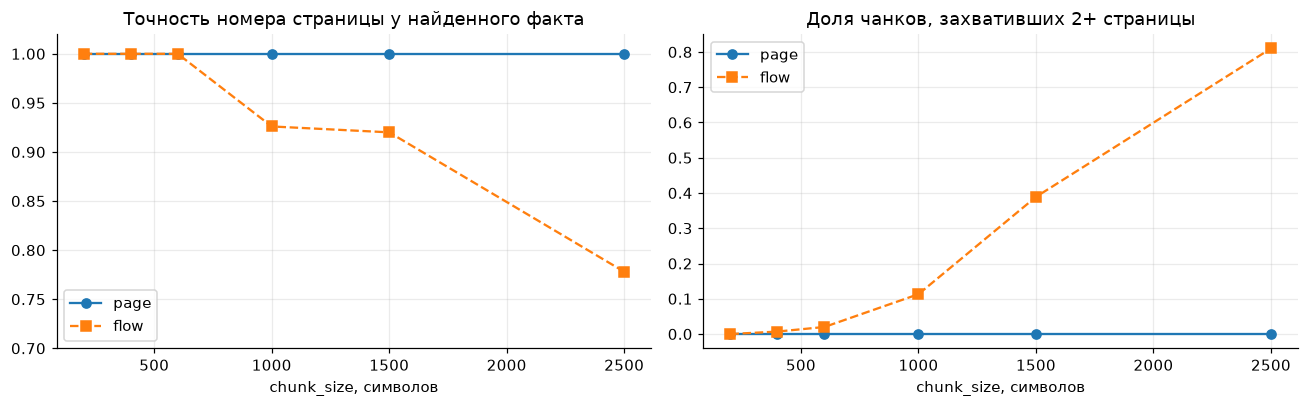

In [15]:
ret = load("exp_retrieval")
df = pd.DataFrame([{k: r[k] for k in ("strategy", "chunk_size", "clean", "chunks", "avg_len",
                                      "multi_page_share", "recall@1", "recall@5", "page_acc")}
                   for r in ret])
df["clean"] = df["clean"].map({True: "", False: "без чистки"})
display(df.rename(columns={"multi_page_share": "доля чанков на 2+ стр.",
                           "page_acc": "точность страницы"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for strat, style in (("page", "o-"), ("flow", "s--")):
    d = df[(df.strategy == strat) & (df.clean == "")]
    ax[0].plot(d.chunk_size, d["page_acc"], style, label=strat)
    ax[1].plot(d.chunk_size, d["multi_page_share"], style, label=strat)
ax[0].set(title="Точность номера страницы у найденного факта", xlabel="chunk_size, символов", ylim=(0.7, 1.02))
ax[1].set(title="Доля чанков, захвативших 2+ страницы", xlabel="chunk_size, символов")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

* При нарезке **внутри страницы** номер верен в 100% случаев при любом размере чанка —
  по построению.
* При **сквозной** нарезке точность падает с ростом чанка: 100% до 600 символов, 93%
  при 1000, **78% при 2500**. Причина видна во втором графике: при 2500 символах 81%
  чанков захватывают две страницы, а `page` у чанка одна — страница его начала. Факт с
  конца такого чанка получает номер предыдущей страницы.
* Recall от размера чанка зависит слабо и немонотонно. Лучший recall@1 даёт 400 символов
  (0.85), он и выбран основным.
* Колонтитулы на поиск почти не влияют (без чистки recall@1 тот же), зато в индекс
  попадают чанки оглавления и титула — что они делают с ответами, разобрано в § 7.3.
* Один факт не находится ни в одной конфигурации с нарезкой по страницам: «можно ли
  постоянно работать через VPN?». Запрет есть в стандарте Zero Trust, но top-5 целиком
  занимают две инструкции по VPN-клиенту — они ближе по словам. Находят его только
  крупные сквозные чанки (1000 и 2500), где запрет склеен с соседним текстом. Это
  ограничение чисто векторного поиска; его лечат гибридный поиск (BM25) или
  реранкинг, которые разбирались на уроке.

Подтверждение на LLM: те же вопросы к индексу «сквозь страницы, 2500 символов».

In [16]:
ch = load("exp_chunks_llm")
rows = []
for key, rs in ch.items():
    for r in rs:
        for f in r["grade"]["facts"]:
            rows.append({"индекс": key, "id": r["id"], "факт": f["needle"][:40],
                         "реальная стр.": ", ".join(str(p) for _, p in f["gold"]),
                         "ссылки в ответе": ", ".join(str(c["page"]) for c in r["citations"]),
                         "подтверждён": "✅" if f["supported"] else "❌"})
t = pd.DataFrame(rows)
display(t[t.id.isin(["D3", "D4"])])

,индекс,id,факт,реальная стр.,ссылки в ответе,подтверждён
4,page-400-80-clean,D3,в течение 48 часов,5,5,✅
5,page-400-80-clean,D4,Apple MacBook Air M2 16GB,7,7,✅
6,page-400-80-clean,D4,PR-4421-M2-16,7,7,✅
16,flow-2500-100-clean,D3,в течение 48 часов,5,4,❌
17,flow-2500-100-clean,D4,Apple MacBook Air M2 16GB,7,6,❌
18,flow-2500-100-clean,D4,PR-4421-M2-16,7,6,❌


Вопросы D3 (48 часов) и D4 (ноутбук ML-инженера): факт лежит на стр. 5 и 7, а чанк
на 2500 символов начинается страницей раньше. Модель добросовестно копирует `стр. 4` и
`стр. 6` из заголовка блока — **ссылка валидна по форме и неверна по существу**. Ни
промпт, ни сама модель тут ничего сделать не могут: ошибка заложена в метаданных при
нарезке.

### 7.2. Теряет ли модель ссылку в длинном ответе

Три многотемных вопроса (L1–L3), каждый в шести вариантах. Метрики:

* **пункты со ссылкой** — доля строк-утверждений (абзац или пункт списка) со ссылкой;
* **блоки со ссылкой** — доля смысловых блоков (до пустой строки или подзаголовка), где
  есть хотя бы одна ссылка. Блок без ссылок — факты, источник которых потерян;
* **строки-перечни** — строки вида «Ссылки: [..][..]», где источники отъехали от фактов.

In [17]:
L = load("exp_long")
rows = []
for r in L:
    c, g = r["coverage"], r["grade"]
    rows.append({"вопрос": r["id"], "поиск": r["retrieval"], "стиль": r["style"], "промпт": r["system"],
                 "токенов ответа": r["usage"]["completion"],
                 "пункты": c["units_cited"], "пунктов": c["units"],
                 "блоки": c["blocks_cited"], "блоков": c["blocks"], "перечни": c["ref_lines"],
                 "факты": g["facts_supported"], "фактов": g["facts_total"]})
L_df = pd.DataFrame(rows)
agg = L_df.groupby(["поиск", "стиль", "промпт"], sort=False).sum(numeric_only=True)
agg["пункты со ссылкой"] = (agg["пункты"] / agg["пунктов"]).map("{:.0%}".format)
agg["блоки со ссылкой"] = (agg["блоки"] / agg["блоков"]).map("{:.0%}".format)
agg["факты подтверждены"] = agg["факты"].astype(str) + "/" + agg["фактов"].astype(str)
agg["токенов (сумма 3)"] = agg["токенов ответа"]
agg[["токенов (сумма 3)", "пункты со ссылкой", "блоки со ссылкой", "перечни", "факты подтверждены"]]

токенов (сумма 3) пункты со ссылкой блоки со ссылкой  перечни факты подтверждены
поиск     стиль       промпт                                                                                  
top8      default     strict               1000              100%             100%        0               6/14
          detailed    strict               1149               96%              89%        0               6/14
decompose default     strict               1485               59%             100%        0               8/14
          detailed    strict               1897              100%             100%        0               8/14
          default     basic                1133                2%               6%        0               0/14
sections  per-section strict               1772               55%              82%        3              11/14

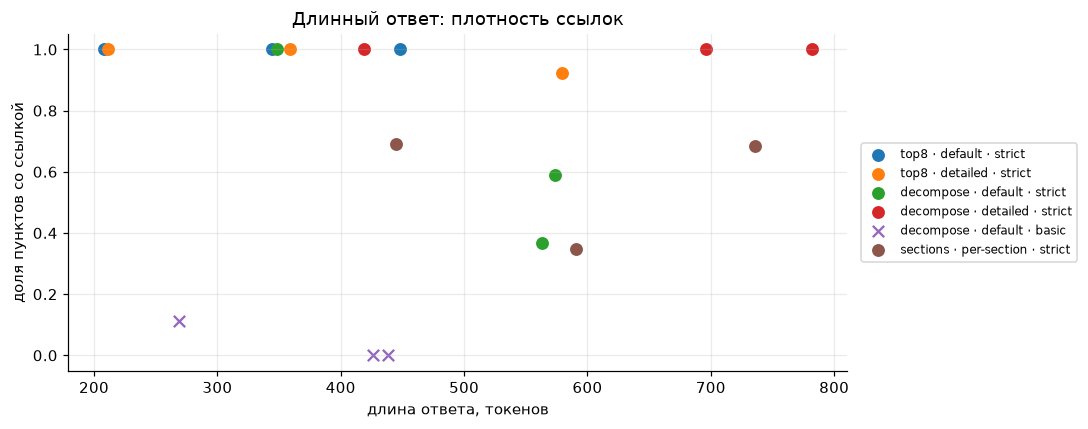

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
for (ret, style, system), d in L_df.groupby(["поиск", "стиль", "промпт"], sort=False):
    ax.scatter(d["токенов ответа"], d["пункты"] / d["пунктов"], s=55,
               label=f"{ret} · {style} · {system}", marker="o" if system == "strict" else "x")
ax.set(xlabel="длина ответа, токенов", ylabel="доля пунктов со ссылкой",
       title="Длинный ответ: плотность ссылок", ylim=(-0.05, 1.05))
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

**Ответ на вопрос задания: да, теряет, но не так, как обычно думают.**

* Со строгим промптом модель **ни разу не потеряла источник целиком** в ответе из одного
  вызова: каждый смысловой блок подписан (16/16). Теряется **гранулярность**: в самых
  длинных ответах (decompose · default, ~500 токенов) ссылкой подписаны лишь 59%
  пунктов (27/46). Модель ставит одну ссылку в конце блока из 3–4 пунктов. Пока блок взят
  из одного фрагмента, это терпимо; когда пункты из разных фрагментов, читатель уже не
  знает, что откуда.
* Явная просьба «распиши каждое правило отдельным абзацем» (`detailed`) возвращает
  100% (42/42) — при этом ответ ещё длиннее. Значит, дело не в длине как таковой, а в
  форме: **списки** модель подписывает поблочно, **абзацы** — поштучно.
* С базовым промптом длинный ответ остаётся почти без ссылок (1 пункт из 43). Правило
  «ссылка в конце каждого пункта» в промпте обязательно.
* Сборка ответа из коротких ответов на подвопросы (`sections`) лучше всего по **фактам**
  (11/14: у каждого подвопроса свой контекст), но **хуже по ссылкам**: в 3 случаях
  модель вынесла источники в отдельную строку «Ссылки: [..][..]» после списка, и 3 блока
  из 17 остались без ссылок. Это именно та «потеря ссылки», которую ищет задание.
* Главная причина неполноты длинных ответов — не генерация, а **поиск**. Один вектор
  многотемного вопроса тянет фрагменты одной-двух тем (top-8 для L1 — только HR), и
  модель честно отвечает «Я не знаю» на остальное. Декомпозиция вопроса на подвопросы
  (одна дешёвая LLM-итерация) это лечит частично: подвопрос «как получить пароли»
  промахивается мимо политики паролей.

### 7.3. Номера страниц: оглавление, колонтитулы и печатная нумерация

Пять вопросов, где пользователь сам спрашивает «на какой странице…». У каждого PDF
печатный номер на 2 меньше физического (титул и оглавление без номеров). Четыре
конфигурации:

| конфигурация | что в индексе | что в заголовке блока контекста |
| --- | --- | --- |
| `clean_strict` | чистые чанки | `стр. N` + готовая ссылка (основная) |
| `raw_strict` | + колонтитулы «— 2 —», титул, оглавление | `стр. N` + готовая ссылка |
| `raw_basic` | + колонтитулы, титул, оглавление; базовый промпт | только `стр. N` |
| `naive_nometa` | `page.get_text()` всего PDF, чанки 1000, **без номера страницы в метаданных** | только имя файла |

In [19]:
P = load("exp_pages")
rows = []
for name, rs in P.items():
    for r in rs:
        v = r["pages"]
        rows.append({"конфигурация": name, "id": r["id"], "физ.": v["physical"], "печ.": v["printed"],
                     "назвала": ", ".join(map(str, sorted(set(v["mentioned"])))),
                     "вердикт": v["verdict"], "оглавление в контексте": "да" if r["toc_in_context"] else ""})
pt = pd.DataFrame(rows)
display(pt.pivot(index="id", columns="конфигурация", values="назвала")
          .assign(**{"физ.": pt.groupby("id")["физ."].first(), "печ.": pt.groupby("id")["печ."].first()}))
pt.groupby("конфигурация", sort=False)["вердикт"].value_counts().unstack(fill_value=0)

конфигурация,clean_strict,naive_nometa,raw_basic,raw_strict,физ.,печ.
id,,,,,,
P1,8,6,8,8,8,6
P2,3,1,3,3,3,1
P3,4,4,4,4,4,2
P4,7,5,7,7,7,5
P5,5,3,5,5,5,3


вердикт,correct,printed
конфигурация,,
clean_strict,5,0
raw_strict,5,0
raw_basic,5,0
naive_nometa,1,4


In [20]:
for r in P["naive_nometa"]:
    print(f"{r['id']}: {r['question']}\n    → {r['answer'].strip()}\n")

P1: На какой странице справочника сотрудника описан заказ такси за счёт компании?
    → Заказ такси за счёт компании описан в главе 9, «Заказ такси за счёт компании», и главе 8, «Инструкция по заказу такси за счёт компании "РобоТех"» [Справочник_сотрудника_HR.pdf, стр. 6, 7].

P2: На какой странице регламентов ИТ находится политика паролей?
    → Политика паролей описана в Главе 1 документа «Регламенты ИТ и информационной безопасности» [Регламенты_ИТ_и_безопасности.pdf, стр. 1].

P3: На какой странице справочника написан срок подачи заявки на отпуск?
    → Срок подачи заявки на отпуск указан на странице 4 [Справочник_сотрудника_HR.pdf, стр. 4].

P4: На какой странице инструкций по закупкам указан стандартный ноутбук для ML-инженеров?
    → Стандартный ноутбук для ML-инженеров указан на странице 5 в главе 7 «Каталог устройств 2026» [Инструкции по офису и закупкам, стр. 5].

P5: На какой странице справочника сказано, что делать при отмене отпуска?
    → [Справочник_сотрудника_HR.pdf, стр

* **Пока номер страницы приходит из метаданных, оглавление и колонтитулы модель не
  сбивают**: 15 из 15 верно во всех трёх конфигурациях с `стр. N` в заголовке блока,
  даже с базовым промптом и даже когда страница оглавления была в контексте (P2, P4).
* **Без метаданных** номер страницы модели взять неоткуда, кроме самого текста, и **4 из
  5 ответов ошибаются ровно на 2** — модель называет напечатанный номер (из колонтитула
  «— N —» или из строки оглавления). P1 показателен: модель перечисляет главы 8 и 9 так,
  как они названы в оглавлении, и ставит их печатные номера «стр. 6, 7». В P4 она
  вдобавок исказила источник: вместо имени файла — название сборника.
* Единственный «верный» ответ (P3) — совпадение: во фрагменте с фактом нет ни одного
  печатного номера, и модель назвала «стр. 4» наугад. **Без метаданных номер страницы —
  либо печатный, либо выдуманный.**

**Вывод.** Главная сложность извлечения номеров страниц из PDF — расхождение трёх
нумераций: физической (индекс страницы в файле, её открывает `#page=N`), печатной
(«— 2 —» в колонтитуле и номера в оглавлении) и логической (PageLabels i, ii, 1, 2…,
которые просмотрщик показывает вместо физических). Оглавление сбивает не поиск, а модель:
оно выглядит как готовый ответ на «на какой странице?». Лечится это не промптом, а
парсингом: номер страницы берётся из структуры PDF и едет в метаданных чанка; текст
колонтитулов и оглавления в индекс не попадает; чанк не пересекает границу страницы.

## 8. Выводы

**Насколько удалось побороть галлюцинации.** На 15 вопросах и 46 ссылках строгого и
базового промптов:

| что проверялось | результат |
| --- | --- |
| выдуманные файлы, страницы, Wiki-статьи | **0** из 46 ссылок |
| провокации вне базы (отпускные дни, ДМС, суточные) | **3/3** «Я не знаю», без единой ссылки |
| прямые вопросы — факт и верная страница | **5/5** строгий, 3/5 базовый |
| факты, подтверждённые ссылкой на страницу, где они на самом деле написаны | **23/32** строгий, 9/32 базовый |
| агрегация из 2+ источников | **1/4**: пропуск второй ссылки, игнор противоречий |

Галлюцинаций **источников** YandexGPT Lite в этой схеме не допускает. Этого удалось
добиться не столько запретами в промпте (базовый промпт тоже не выдумал ни одной
страницы), сколько тем, что модель ничего не вычисляет: готовая ссылка лежит в
заголовке блока, ей остаётся её скопировать. Остающиеся ошибки другого рода:

1. **Ссылка валидна по форме, но не подтверждает факт.** Сквозной чанк начался страницей
   раньше (§ 7.1), или модель сослалась на соседний документ про того же человека (D5,
   базовый промпт). Формальная проверка «источник был в контексте» такие ошибки не
   ловит — нужна сверка с текстом страницы.
2. **Недосказанность вместо выдумки.** Модель не придумывает недостающее, а молча
   опускает: вторую ссылку в агрегации, второй из противоречащих документов, тему,
   которую не нашёл поиск.
3. **Потеря гранулярности в длинных списках:** одна ссылка на блок вместо ссылки на
   пункт, иногда — перечень источников в конце.

**Главная сложность с номерами страниц** — три разные нумерации в одном PDF
(физическая, печатная, PageLabels) и то, что печатная видна в тексте страницы и в
оглавлении. Если номер страницы не приходит в метаданных, модель берёт печатный и
ошибается ровно на число ненумерованных страниц (4 из 5). Если чанк режется сквозь
страницы, он получает номер своей первой страницы, и точность падает до 78% на
чанках 2500 символов. Оба дефекта устраняются только на этапе парсинга и нарезки.

**Что бы я сделал дальше:** гибридный поиск BM25 + векторы и реранкер (запрос про VPN
не находится чисто векторным поиском); фильтр по метаданным `year=2026` и пометке
«архив», чтобы архивные политики не спорили с действующими; пост-проверку ответа —
ссылки на страницы, где не встречаются ключевые слова утверждения, помечать в
интерфейсе как непроверенные.

In [21]:
import glob
calls = [json.loads(Path(f).read_text(encoding="utf-8")) for f in glob.glob(str(config.LLM_CACHE / "*.json"))]
tok = sum(c["prompt_tokens"] + c["completion_tokens"] for c in calls)
print(f"Вызовов YandexGPT: {len(calls)}, токенов: {tok:,}, стоимость ≈ {tok/1000*config.price_per_1k(config.YC_MODEL):.0f} ₽ "
      f"(тариф Lite {config.price_per_1k(config.YC_MODEL)} ₽ / 1000 токенов)".replace(",", " "))

Вызовов YandexGPT: 113  токенов: 121 123  стоимость ≈ 24 ₽ (тариф Lite 0.2 ₽ / 1000 токенов)
